In [1]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("Device count:", torch.cuda.device_count())
if torch.cuda.is_available():
    print("Device name:", torch.cuda.get_device_name(0))

CUDA available: True
Device count: 2
Device name: Tesla T4


In [1]:
%pip install -q timm datasets
import torch, timm, numpy as np
from datasets import load_dataset
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", DEVICE)

TRAIN_PER_CLASS = 3000
TEST_PER_CLASS  = 500
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 5

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mlflow 3.3.2 requires pyarrow<22,>=4.0.0, but you have pyarrow 25.0.1 which is incompatible.


KeyboardInterrupt: 

In [13]:
def norm_label(l):
    if isinstance(l, str):
        return 0 if l.lower() in ('real','nature','natural') else 1
    return int(l)

real_imgs, fake_imgs = [], []
target = TRAIN_PER_CLASS + TEST_PER_CLASS

ds = load_dataset("TheKernel01/Tiny-GenImage", split="train", streaming=True)

for i, s in enumerate(ds):
    lbl = norm_label(s['label'])
    img = s['image'].convert('RGB')
    if lbl == 0 and len(real_imgs) < target:
        real_imgs.append(img)
    elif lbl == 1 and len(fake_imgs) < target:
        fake_imgs.append(img)
    if len(real_imgs) >= target and len(fake_imgs) >= target:
        break

print(f"real: {len(real_imgs)} | fake: {len(fake_imgs)}")

real: 3500 | fake: 3500


In [14]:
import random
random.seed(42)

# Shuffle both lists before split
random.shuffle(real_imgs)
random.shuffle(fake_imgs)

train_real, test_real = real_imgs[:TRAIN_PER_CLASS], real_imgs[TRAIN_PER_CLASS:]
train_fake, test_fake = fake_imgs[:TRAIN_PER_CLASS], fake_imgs[TRAIN_PER_CLASS:]

# Stronger augmentation
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])
test_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

class DS(Dataset):
    def __init__(self, reals, fakes, tf):
        self.items = [(i,0) for i in reals] + [(i,1) for i in fakes]
        self.tf = tf
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        img, lbl = self.items[i]
        return self.tf(img), lbl

train_ds = DS(train_real, train_fake, train_tf)
test_ds  = DS(test_real,  test_fake,  test_tf)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train: {len(train_ds)} | Test: {len(test_ds)}")

Train: 6000 | Test: 1000


In [15]:
model = timm.create_model('efficientnet_b0', pretrained=True, num_classes=2).to(DEVICE)
crit = torch.nn.CrossEntropyLoss()
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
scaler = torch.amp.GradScaler('cuda')

for ep in range(EPOCHS):
    model.train()
    loss_sum, correct, total = 0, 0, 0
    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        opt.zero_grad()
        with torch.amp.autocast('cuda'):
            out = model(x)
            loss = crit(out, y)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        loss_sum += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        total += y.size(0)
    scheduler.step()
    print(f"Epoch {ep+1}/{EPOCHS} | loss {loss_sum/total:.4f} | acc {correct/total*100:.2f}%")

Epoch 1/5 | loss 1.4004 | acc 68.55%
Epoch 2/5 | loss 0.4974 | acc 84.88%
Epoch 3/5 | loss 0.2603 | acc 90.32%
Epoch 4/5 | loss 0.1857 | acc 92.87%
Epoch 5/5 | loss 0.1636 | acc 94.05%


In [16]:
model.eval()
preds, labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        out = model(x.to(DEVICE))
        preds.extend(out.argmax(1).cpu().numpy())
        labels.extend(y.numpy())

preds, labels = np.array(preds), np.array(labels)

print("Test Report:")
print(classification_report(labels, preds, target_names=['Real','AI'], digits=3))

cm = confusion_matrix(labels, preds)
print("Confusion Matrix:\n", cm)
print(f"\nFinal Accuracy: {(preds==labels).mean()*100:.2f}%")

torch.save(model.state_dict(), 'truthlens_b0_v1.pt')
print("Model saved: truthlens_b0_v1.pt")

Test Report:
              precision    recall  f1-score   support

        Real      0.779     0.890     0.831       500
          AI      0.872     0.748     0.805       500

    accuracy                          0.819      1000
   macro avg      0.826     0.819     0.818      1000
weighted avg      0.826     0.819     0.818      1000

Confusion Matrix:
 [[445  55]
 [126 374]]

Final Accuracy: 81.90%
Model saved: truthlens_b0_v1.pt


In [18]:
from PIL import Image
import random

idx = random.randint(0, len(test_ds)-1)
img_tensor, true_lbl = test_ds[idx]

with torch.no_grad():
    out = model(img_tensor.unsqueeze(0).to(DEVICE))
    probs = torch.softmax(out, dim=1)[0]
    pred_lbl = probs.argmax().item()

names = ['Real', 'AI-Generated']
print(f"True: {names[true_lbl]}")
print(f"Predicted: {names[pred_lbl]} ({probs[pred_lbl]*100:.2f}%)")

True: AI-Generated
Predicted: AI-Generated (99.67%)


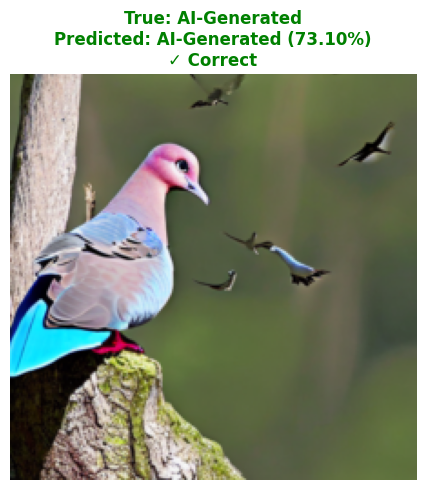

In [19]:
from PIL import Image
import matplotlib.pyplot as plt
import random

# Random test image uthao
idx = random.randint(0, len(test_ds)-1)
img_tensor, true_lbl = test_ds[idx]

# Prediction
with torch.no_grad():
    out = model(img_tensor.unsqueeze(0).to(DEVICE))
    probs = torch.softmax(out, dim=1)[0]
    pred_lbl = probs.argmax().item()

names = ['Real', 'AI-Generated']

# Image ko display ke liye un-normalize karo
mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
img_display = img_tensor * std + mean          # denormalize
img_display = img_display.clamp(0, 1)          # valid range
img_display = img_display.permute(1, 2, 0)     # CHW -> HWC
img_display = img_display.numpy()

# Plot
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(img_display)
ax.axis('off')

# Color: green if correct, red if wrong
correct = (pred_lbl == true_lbl)
color = 'green' if correct else 'red'

title = (
    f"True: {names[true_lbl]}\n"
    f"Predicted: {names[pred_lbl]} ({probs[pred_lbl]*100:.2f}%)\n"
    f"{'✓ Correct' if correct else '✗ Wrong'}"
)
ax.set_title(title, fontsize=12, color=color, fontweight='bold')
plt.tight_layout()
plt.show()

In [20]:
from IPython.display import display
import ipywidgets as widgets
import io
from PIL import Image

upload = widgets.FileUpload(accept='image/*', multiple=False)
display(upload)

FileUpload(value=(), accept='image/*', description='Upload')

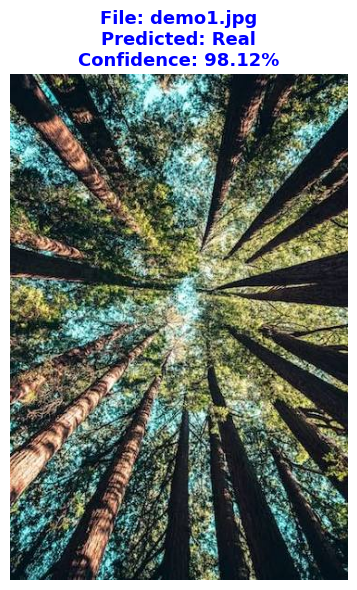

File:       demo1.jpg
Prediction: Real
Real prob:  98.12%
AI prob:    1.88%


In [23]:
from PIL import Image
import matplotlib.pyplot as plt
import io
import torch

# Uploaded image uthao
if len(upload.value) == 0:
    print("⚠️ Pehle upar wale button se image upload karo")
else:
    file_info = upload.value[0]
    content = file_info['content']
    original_name = file_info['name']
    
    # Load
    img = Image.open(io.BytesIO(content)).convert('RGB')
    
    # Preprocess
    transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
    ])
    img_tensor = transform(img)
    
    # Predict
    model.eval()
    with torch.no_grad():
        out = model(img_tensor.unsqueeze(0).to(DEVICE))
        probs = torch.softmax(out, dim=1)[0]
        pred_lbl = probs.argmax().item()
    
    names = ['Real', 'AI-Generated']
    
    # Display
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(
        f"File: {original_name}\n"
        f"Predicted: {names[pred_lbl]}\n"
        f"Confidence: {probs[pred_lbl]*100:.2f}%",
        fontsize=13, fontweight='bold',
        color='green' if pred_lbl == 1 else 'blue'
    )
    plt.tight_layout()
    plt.show()
    
    print("="*40)
    print(f"File:       {original_name}")
    print(f"Prediction: {names[pred_lbl]}")
    print(f"Real prob:  {probs[0]*100:.2f}%")
    print(f"AI prob:    {probs[1]*100:.2f}%")
    print("="*40)

In [1]:
from IPython.display import display
import ipywidgets as widgets
import io
from PIL import Image

upload = widgets.FileUpload(accept='image/*', multiple=False)
display(upload)

FileUpload(value={}, accept='image/*', description='Upload')

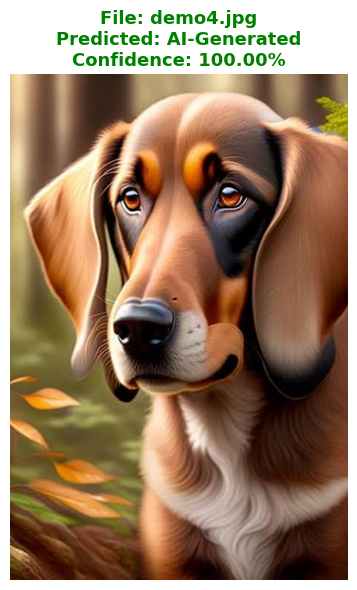

File:       demo4.jpg
Prediction: AI-Generated
Real prob:  0.00%
AI prob:    100.00%


In [37]:
from PIL import Image
import matplotlib.pyplot as plt
import io
import torch

# Uploaded image uthao
if len(upload.value) == 0:
    print("⚠️ Pehle upar wale button se image upload karo")
else:
    file_info = upload.value[0]
    content = file_info['content']
    original_name = file_info['name']
    
    # Load
    img = Image.open(io.BytesIO(content)).convert('RGB')
    
    # Preprocess
    transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
    ])
    img_tensor = transform(img)
    
    # Predict
    model.eval()
    with torch.no_grad():
        out = model(img_tensor.unsqueeze(0).to(DEVICE))
        probs = torch.softmax(out, dim=1)[0]
        pred_lbl = probs.argmax().item()
    
    names = ['Real', 'AI-Generated']
    
    # Display
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(
        f"File: {original_name}\n"
        f"Predicted: {names[pred_lbl]}\n"
        f"Confidence: {probs[pred_lbl]*100:.2f}%",
        fontsize=13, fontweight='bold',
        color='green' if pred_lbl == 1 else 'blue'
    )
    plt.tight_layout()
    plt.show()
    
    print("="*40)
    print(f"File:       {original_name}")
    print(f"Prediction: {names[pred_lbl]}")
    print(f"Real prob:  {probs[0]*100:.2f}%")
    print(f"AI prob:    {probs[1]*100:.2f}%")
    print("="*40)

Device: cpu
Model file exists: True
Current folder: c:\4th Year 2nd Term\Web Programming And Mobile Application Project\Week4
✅ Model loaded

📷 ORIGINAL IMAGE SIZE: 417x626 pixels



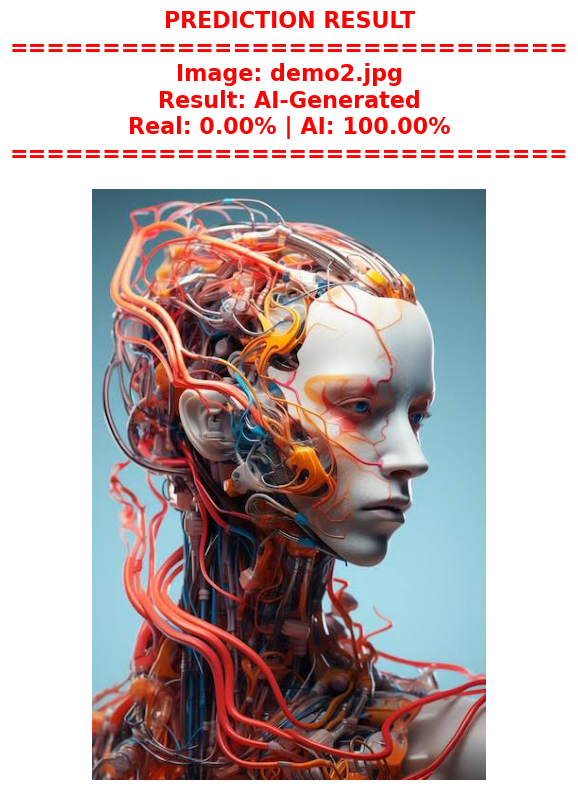


                   FINAL RESULT                   
File:              demo2.jpg
Size:              417x626
PREDICTION:        AI-GENERATED
Real Probability:  0.00%
AI Probability:    100.00%



In [ ]:
import torch
import timm
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
import os
import numpy as np

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
IMG_SIZE = 224
MODEL_PATH = "truthlens_b0_v1.pt"

print("Device:", DEVICE)
print("Model file exists:", os.path.exists(MODEL_PATH))
print("Current folder:", os.getcwd())

# Load model
model = timm.create_model('efficientnet_b0', pretrained=False, num_classes=2)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model = model.to(DEVICE)
model.eval()
print("✅ Model loaded\n")

# Image path
IMG_PATH = "demo3.jpg"

if os.path.exists(IMG_PATH):
    img = Image.open(IMG_PATH).convert('RGB')
    
    # Print actual image size
    original_width, original_height = img.size
    print(f"📷 ORIGINAL IMAGE SIZE: {original_width}x{original_height} pixels")
    print()
    
    transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
    ])
    img_tensor = transform(img)
    
    with torch.no_grad():
        out = model(img_tensor.unsqueeze(0).to(DEVICE))
        probs = torch.softmax(out, dim=1)[0]
        pred_lbl = probs.argmax().item()
    
    names = ['Real', 'AI-Generated']
    
    # Use ORIGINAL image for display (not resized)
    img_display = np.array(img)
    
    # Calculate dynamic figure size based on original image dimensions
    dpi = 100
    figsize_width = original_width / dpi
    figsize_height = original_height / dpi
    # Ensure minimum size for visibility
    figsize_width = max(figsize_width, 8)
    figsize_height = max(figsize_height, 8)
    
    # Plot with original size
    fig, ax = plt.subplots(figsize=(figsize_width, figsize_height), dpi=dpi)
    ax.imshow(img_display)
    ax.axis('off')
    
    color = 'green' if pred_lbl == 0 else 'red'
    prediction_text = names[pred_lbl]
    
    title = (
        f"PREDICTION RESULT\n"
        f"{'='*30}\n"
        f"Image: {IMG_PATH}\n"
        f"Result: {prediction_text}\n"
        f"Real: {probs[0]*100:.2f}% | AI: {probs[1]*100:.2f}%\n"
        f"{'='*30}"
    )
    ax.set_title(title, fontsize=16, fontweight='bold', color=color, pad=20)
    plt.tight_layout()
    plt.show()
    
    # Large clear output
    print("\n" + "="*50)
    print("FINAL RESULT".center(50))
    print("="*50)
    print(f"File:              {IMG_PATH}")
    print(f"Size:              {original_width}x{original_height}")
    print(f"PREDICTION:        {prediction_text.upper()}")
    print(f"Real Probability:  {probs[0]*100:.2f}%")
    print(f"AI Probability:    {probs[1]*100:.2f}%")
    print("="*50 + "\n")
    
else:
    print(f"⚠️ Image file not found: {IMG_PATH}")